# 08 — Curva adversarial de desempenho por mudança no mix de grupos

> **Versão SPW=13.882494684620836; corte fixo 0,50.** O modelo congelado veio do retreino documentado em 00; o Booster e o manifesto estão em `models/`.

**Pergunta.** Entre as composições formadas por grupos de perfis históricos completos, como Brier, AUC ROC, PR-AUC trapezoidal e KS do modelo variam quando damos mais peso a grupos com maior erro de Brier? Recall e precisão em 0,50 são referenciais, sem papel de parada.

1. Formamos 20 grupos usando somente $X$ do treino; nenhuma informação de desfecho entra no agrupamento.
2. Dividimos o holdout rotulado em exploração e confirmação. O erro médio por grupo na exploração determina os pesos. A confirmação avalia os mesmos grupos e intensidades em linhas não usadas na escolha dos erros.
3. Para cada intensidade $\theta\ge0$, a participação é $q_g\propto p_g\exp(\theta L_g)$, com $p_g$ a participação basal e $L_g$ o Brier médio do grupo na exploração. Essa forma resolve a busca por alta perda com penalização KL dentro da família de misturas escolhida.
4. Calculamos KL, PSI de grupos, ESS e as quatro métricas em ambas as metades. As curvas descrevem **respostas**, sem declarar aprovação, reprovação ou tolerância universal.

A ponderação preserva linhas observadas e seus rótulos. Ainda exige estabilidade aproximada de $P(Y\mid X)$, suporte dos grupos e representatividade do holdout; não mede desfecho em `cs-test.csv`, que é sem rótulos. A busca maximiza Brier **na exploração**; não é um pior caso matemático simultâneo de AUC, PR-AUC ou KS.

Fontes: [Namkoong e Duchi, NeurIPS 2016](https://papers.nips.cc/paper_files/paper/2016/hash/4588e674d3f0faf985047d4c3f13ed0d-Abstract.html); [Subbaswamy et al., AISTATS 2021](https://proceedings.mlr.press/v130/subbaswamy21a.html).

In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import roc_curve, precision_recall_curve, auc
import xgboost as xgb
from IPython.display import display

SEED=33
P=DATA_DIR_PROJECT
DATA_DIR=next((d for d in (P,P.parent) if (d/'cs-training.csv').is_file()),None)
if DATA_DIR is None:
    raise FileNotFoundError('Coloque os CSVs em data/raw/ e execute a partir da raiz do projeto ou de notebooks/.')
OUT_DIR = TABLES_DIR
FEATURES=[
 'RevolvingUtilizationOfUnsecuredLines','age','NumberOfTime30-59DaysPastDueNotWorse',
 'DebtRatio','MonthlyIncome','NumberOfOpenCreditLinesAndLoans','NumberOfTimes90DaysLate',
 'NumberRealEstateLoansOrLines','NumberOfTime60-89DaysPastDueNotWorse','NumberOfDependents']
sns.set_theme(style='whitegrid')

In [3]:
# Verifica que o modelo, o manifesto e a configuração deste estudo coincidem.
import hashlib as _hashlib
import json as _json
_manifesto_versao = _json.loads(
    (MODEL_DIR / "manifesto_modelo.json").read_text(encoding="utf-8")
)
assert abs(_manifesto_versao["params_fornecidos"]["scale_pos_weight"]
           - 13.882494684620836) < 1e-12
assert _manifesto_versao["cutoff"] == 0.5
assert _manifesto_versao["features"] == FEATURES
_arquivo_modelo_versao = MODEL_DIR / "model_class_retreinado.json"
assert _hashlib.sha256(_arquivo_modelo_versao.read_bytes()).hexdigest() == \
       _manifesto_versao["model_sha256"], "Booster e manifesto divergentes."
print("Modelo validado:", _manifesto_versao["variant"])


Modelo validado: metricas_brier_auc_prauc_ks_grade_5a50


## 1. Reconstruir somente a divisão e os scores

O modelo é carregado do artefato salvo; não treinamos nem calibramos árvores aqui. O cutoff permanece 0,50.

In [4]:
df=pd.read_csv(DATA_DIR/'cs-training.csv').drop(columns=['Unnamed: 0'])
X=df[FEATURES];y=df['SeriousDlqin2yrs'].astype(int)
X_tv,X_hold,y_tv,y_hold=train_test_split(X,y,test_size=.15,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_tv,y_tv,test_size=.1765,random_state=SEED)
model=xgb.Booster();model.load_model(str(MODEL_DIR / 'model_class_retreinado.json'))
model.set_param({'device':'cpu'})
p_hold=model.predict(xgb.DMatrix(X_hold,feature_names=FEATURES,enable_categorical=True),iteration_range=(0,model.num_boosted_rounds()))
yy=np.asarray(y_hold,dtype=int)
dev_idx,confirm_idx=train_test_split(np.arange(len(yy)),test_size=.5,random_state=2026,stratify=yy)
print(f'Modelo: {model.num_boosted_rounds()} árvores; exploração {len(dev_idx):,}, confirmação {len(confirm_idx):,}')

Modelo: 103 árvores; exploração 11,250, confirmação 11,250


## 2. Definir grupos de perfil usando apenas as entradas

Cada coluna é transformada em posto normal aproximado em relação a `X_train`; ausentes viram uma indicação separada. O agrupamento em 20 células aproxima regiões conjuntas do espaço de entradas. Ele é ajustado em uma amostra do treino **sem usar o alvo nem as previsões**. Os grupos têm tamanhos variados; grupos raros limitam a precisão dos resultados.


In [5]:
reference={f:np.sort(X_train[f].dropna().to_numpy(dtype=float)) for f in FEATURES}
def rank_features(frame):
    n=len(frame);z=np.zeros((n,len(FEATURES)),dtype=np.float32)
    missing=np.zeros_like(z)
    for j,f in enumerate(FEATURES):
        v=frame[f].to_numpy(dtype=float)
        valid=np.isfinite(v)
        r=reference[f]
        left=np.searchsorted(r,v[valid],side='left')
        right=np.searchsorted(r,v[valid],side='right')
        u=np.clip((left+right+1)/(2*(len(r)+1)),1/(len(r)+1),len(r)/(len(r)+1))
        z[valid,j]=np.clip(norm.ppf(u),-3,3)
        missing[~valid,j]=1
    return np.column_stack([z,missing*1.5])

fit_sample=X_train.sample(min(35000,len(X_train)),random_state=SEED)
cluster=MiniBatchKMeans(n_clusters=20,batch_size=2048,n_init=5,max_iter=120,random_state=SEED)
cluster.fit(rank_features(fit_sample))
grp=cluster.predict(rank_features(X_hold))
counts=np.bincount(grp,minlength=20)
print('Grupos: mínimo',counts.min(),'mediana',np.median(counts),'máximo',counts.max())
display(pd.DataFrame({'grupo':np.arange(20),'n_holdout':counts}).sort_values('n_holdout'))

Grupos: mínimo 686 mediana 1035.0 máximo 1835


,grupo,n_holdout
14,14,686
16,16,730
17,17,751
4,4,867
8,8,901
3,3,905
11,11,983
19,19,986
9,9,1008
5,5,1030


## 3. Métricas ponderadas e pesos adversariais

A busca utiliza **somente** Brier médio por grupo da metade de exploração. A cada $\theta$, todos os registros do mesmo grupo recebem o mesmo multiplicador, independentemente do próprio rótulo. O ESS, $((\sum_i w_i)^2/\sum_i w_i^2)/n$, diminui quando poucos registros dominam os resultados; nós o mostramos continuamente, sem limite de aprovação.

AUC ROC é a área trapezoidal sob TPR versus FPR; **KS do modelo** é $\max_t[\mathrm{TPR}(t)-\mathrm{FPR}(t)]$. **PR-AUC trapezoidal** integra a precisão ao longo do recall; AP é a soma em degraus e aparece separadamente. Brier é a média ponderada de $(y-\hat p)^2$. Recall e precisão são calculados só no corte 0,50. Todas usam o mesmo conjunto de pesos por cenário.
Como as frequências basais dos grupos podem diferir entre exploração e confirmação, registramos KL e PSI realizados **em cada metade**. Os multiplicadores são aprendidos na exploração e aplicados sem reajuste na confirmação.


In [6]:
def metrics(idx,w):
    y0=yy[idx];p0=p_hold[idx];w0=np.asarray(w,dtype=float)
    assert np.all(w0>=0) and w0.sum()>0
    fpr,tpr,_=roc_curve(y0,p0,sample_weight=w0)
    precision_curve,recall_curve,_=precision_recall_curve(y0,p0,sample_weight=w0)
    pred=p0>=.5
    tp=w0[(y0==1)&pred].sum();fn=w0[(y0==1)&~pred].sum()
    fp=w0[(y0==0)&pred].sum();tn=w0[(y0==0)&~pred].sum()
    prev=np.average(y0,weights=w0)
    ap=float(-np.sum(np.diff(recall_curve)*precision_curve[:-1]))
    return {'auc':float(auc(fpr,tpr)),
            'prauc_trap':float(auc(recall_curve,precision_curve)),
            'ks_modelo':float(np.max(tpr-fpr)),
            'ap':ap,'ap_lift':ap/prev,
            'brier':np.average((y0-p0)**2,weights=w0),
            'recall':tp/(tp+fn),'precision':tp/(tp+fp) if tp+fp else np.nan,
            'fpr':fp/(fp+tn),'prevalencia':prev,
            'ess_fracao':w0.sum()**2/np.square(w0).sum()/len(w0)}

base_dev=metrics(dev_idx,np.ones(len(dev_idx)))
base_confirm=metrics(confirm_idx,np.ones(len(confirm_idx)))
p_dev=np.bincount(grp[dev_idx],minlength=20).astype(float);p_dev/=p_dev.sum()
p_confirm=np.bincount(grp[confirm_idx],minlength=20).astype(float);p_confirm/=p_confirm.sum()
loss=(yy-p_hold)**2
group_loss=np.bincount(grp[dev_idx],weights=loss[dev_idx],minlength=20)/np.bincount(grp[dev_idx],minlength=20)
assert np.isfinite(group_loss).all()
central=['brier','auc','prauc_trap','ks_modelo']
rows=[]
THETA_GRID=np.r_[np.linspace(0,2.5,126),np.linspace(5,300,119)]
for theta in THETA_GRID:
    logq=np.log(p_dev)+theta*(group_loss-group_loss.max())
    q=np.exp(logq-logq.max());q/=q.sum()
    multiplier=q/p_dev
    wd=multiplier[grp[dev_idx]];wc=multiplier[grp[confirm_idx]]
    md=metrics(dev_idx,wd);mc=metrics(confirm_idx,wc)
    kl=float(np.sum(q*np.log(q/p_dev)))
    psi=float(np.sum((q-p_dev)*np.log(q/p_dev)))
    q_confirm=np.bincount(grp[confirm_idx],weights=wc,minlength=20).astype(float)
    q_confirm/=q_confirm.sum()
    kl_confirm=float(np.sum(q_confirm*np.log(q_confirm/p_confirm)))
    psi_confirm=float(np.sum((q_confirm-p_confirm)*np.log(q_confirm/p_confirm)))
    rows.append({'theta':theta,'kl_grupos_dev':kl,'psi_grupos_dev':psi,
                 'kl_grupos_confirm':kl_confirm,'psi_grupos_confirm':psi_confirm,
                 'grupo_max_peso':int(np.argmax(multiplier)),'multiplicador_max':multiplier.max(),
                 **{f'{k}_dev':v for k,v in md.items()},
                 **{f'{k}_confirm':v for k,v in mc.items()},
                 **{f'delta_{k}_dev':md[k]-base_dev[k] for k in central},
                 **{f'delta_{k}_confirm':mc[k]-base_confirm[k] for k in central}})
result=pd.DataFrame(rows)
result.to_csv(OUT_DIR/'resultados_dro_grupos.csv',index=False,encoding='utf-8-sig')
display(pd.DataFrame([{'amostra':'exploração',**base_dev},{'amostra':'confirmação',**base_confirm}]).round(4))
display(result.iloc[[0,5,20,50,100,125,170,244]][
    ['theta','kl_grupos_dev','psi_grupos_dev','ess_fracao_confirm',
     'delta_brier_confirm','delta_auc_confirm','delta_prauc_trap_confirm','delta_ks_modelo_confirm']].round(5))

,amostra,auc,prauc_trap,ks_modelo,ap,ap_lift,brier,recall,precision,fpr,prevalencia,ess_fracao
0,exploração,0.8683,0.4000,0.5913,0.4006,6.0090,0.1428,0.7947,0.2170,0.2049,0.0667,1.0
1,confirmação,0.8654,0.3932,0.5899,0.3941,5.9108,0.1453,0.7933,0.2136,0.2087,0.0667,1.0


,theta,kl_grupos_dev,psi_grupos_dev,ess_fracao_confirm,delta_brier_confirm,delta_auc_confirm,delta_prauc_trap_confirm,delta_ks_modelo_confirm
0,0.0,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000,0.00000
5,0.1,0.00007,0.00014,0.99986,0.00142,0.00029,0.00234,0.00048
20,0.4,0.00114,0.00225,0.99762,0.00581,0.00105,0.00922,0.00147
50,1.0,0.00750,0.01467,0.98401,0.01512,0.00203,0.02241,0.00332
100,2.0,0.03256,0.06255,0.93068,0.03221,0.00191,0.04245,0.00030
125,2.5,0.05280,0.10066,0.88950,0.04145,0.00099,0.05151,-0.00437
170,115.0,3.06620,33.18770,0.04589,0.28289,-0.13905,0.09256,-0.22653
244,300.0,3.25737,86.95151,0.04182,0.28345,-0.14656,0.07715,-0.24010


## 4. Extremos observados na grade e confirmação

A tabela abaixo localiza o **maior aumento de Brier** e as **maiores reduções de AUC, PR-AUC trapezoidal e KS** na metade de confirmação, sem declarar uma primeira falha. São extremos de uma grade escolhida e não uma garantia de pior caso para qualquer população futura. Para reproduzir em outro modelo, ajuste somente os grupos, o intervalo de $\theta$, o conjunto de exploração/confirmação e a função de perda usada na busca; mantenha a definição de cada métrica fixa.

In [7]:
extremos=[]
for metrica in central:
    col='delta_'+metrica+'_confirm'
    idx=result[col].idxmax() if metrica=='brier' else result[col].idxmin()
    row=result.loc[idx]
    extremos.append({'metrica':metrica,'theta':row.theta,
                     'kl_grupos_dev':row.kl_grupos_dev,'psi_grupos_dev':row.psi_grupos_dev,
                     'ess_fracao_confirm':row.ess_fracao_confirm,
                     'valor_confirmacao':row[f'{metrica}_confirm'],
                     'delta_confirmacao':row[col]})
display(pd.DataFrame(extremos).round(5))
print('ESS/n na confirmação (mínimo/mediana/máximo):',
      result.ess_fracao_confirm.quantile([0,.5,1]).round(4).to_dict())

,metrica,theta,kl_grupos_dev,psi_grupos_dev,ess_fracao_confirm,valor_confirmacao,delta_confirmacao
0,brier,300.0,3.25737,86.95151,0.04182,0.42871,0.28345
1,auc,300.0,3.25737,86.95151,0.04182,0.71883,-0.14656
2,prauc_trap,0.0,0.00000,0.00000,1.00000,0.39316,0.00000
3,ks_modelo,300.0,3.25737,86.95151,0.04182,0.34980,-0.24010


ESS/n na confirmação (mínimo/mediana/máximo): {0.0: 0.0418, 0.5: 0.8949, 1.0: 1.0}


### Incerteza em uma intensidade pré-especificada

Para exemplificar intervalos, escolhemos $\theta=20$ **antes de olhar as quatro métricas**, aproximando pelo ponto da grade mais próximo. Reamostramos 200 vezes as linhas da metade de confirmação e calculamos deltas pareados contra a sua própria linha de base. Isso não define parada. O intervalo continua condicional ao modelo, agrupamento e perdas estimadas na exploração; não cobre incerteza sobre o mecanismo futuro.

In [8]:
theta_star=float(result.iloc[np.argmin(np.abs(result.theta.to_numpy()-20.0))].theta)
linha_confirmada=result.loc[np.isclose(result.theta,theta_star)].iloc[0]
print(f'Intensidade pré-especificada: θ solicitado 20; θ na grade {theta_star:.3f}; '
      f'KL {linha_confirmada.kl_grupos_dev:.4f}; PSI grupos {linha_confirmada.psi_grupos_dev:.4f}')
logq=np.log(p_dev)+theta_star*(group_loss-group_loss.max())
q=np.exp(logq-logq.max());q/=q.sum()
weights_confirm=(q/p_dev)[grp[confirm_idx]]
rng=np.random.default_rng(SEED+2026)
delta_rows=[]
for _ in range(200):
    take=rng.integers(0,len(confirm_idx),len(confirm_idx))
    index=confirm_idx[take]
    b0=metrics(index,np.ones(len(index)))
    s=metrics(index,weights_confirm[take])
    delta_rows.append({k:s[k]-b0[k] for k in central})
deltas=pd.DataFrame(delta_rows)
ci=pd.DataFrame({'delta_observado':{k:linha_confirmada[f'delta_{k}_confirm'] for k in central},
                 'ic95_inferior':deltas.quantile(.025),'ic95_superior':deltas.quantile(.975)})
display(ci.round(5))

Intensidade pré-especificada: θ solicitado 20; θ na grade 20.000; KL 1.9515; PSI grupos 5.2020


,delta_observado,ic95_inferior,ic95_superior
brier,0.25956,0.24430,0.27405
auc,-0.10770,-0.13609,-0.08432
prauc_trap,0.14058,0.11851,0.16116
ks_modelo,-0.18083,-0.22755,-0.12390


## 5. Curvas e composição adversarial

Cada curva mostra a métrica em exploração e confirmação ao variar a divergência KL da mistura dos 20 grupos. A distância horizontal é o deslocamento realizado; não representa tempo. Brier maior e AUC/PR-AUC/KS menores indicam deterioração descritiva. O ESS acompanha a concentração dos pesos. Não há linha horizontal de aceite/rejeição.

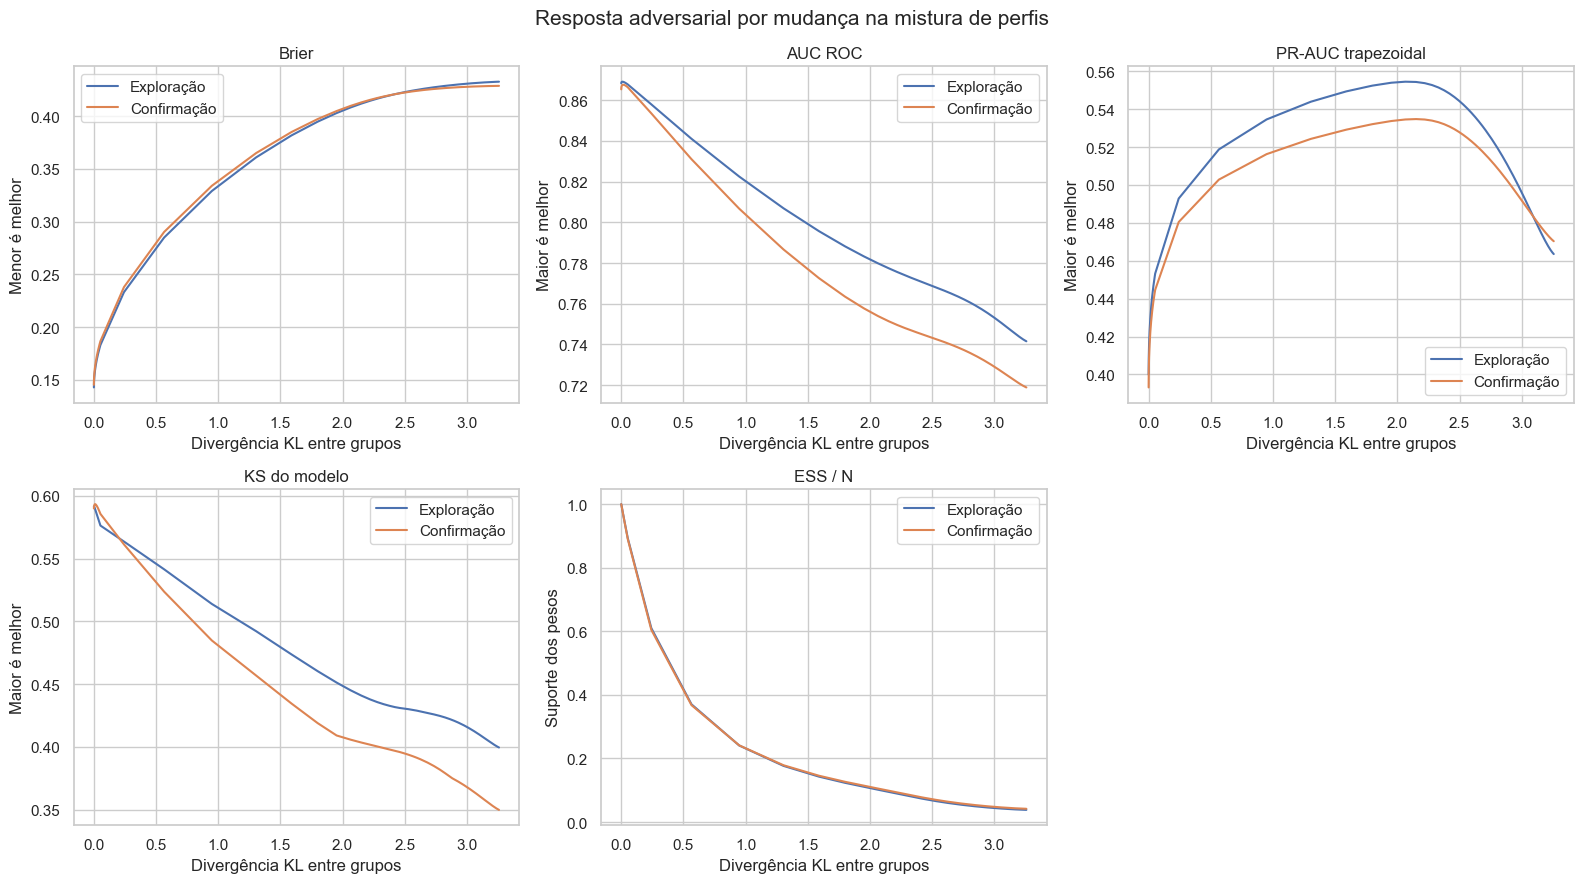

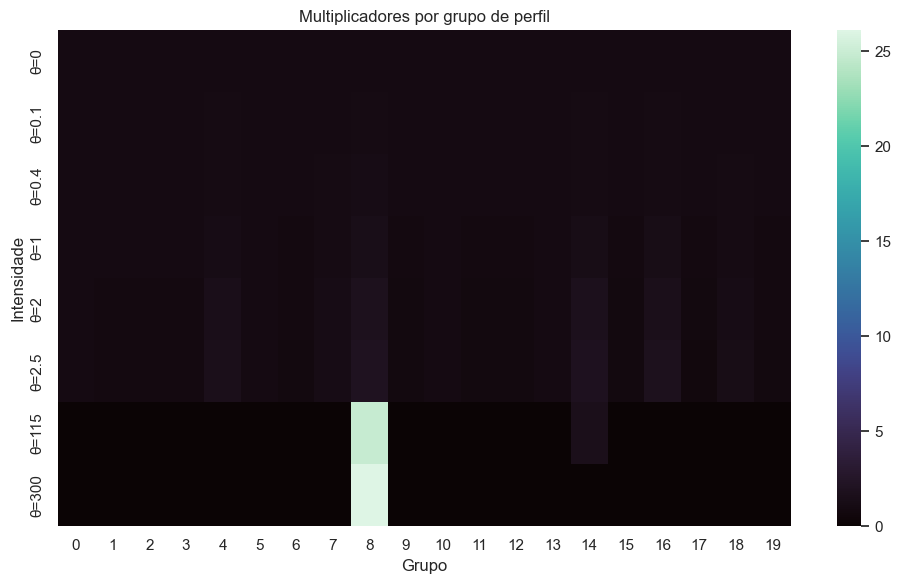

In [9]:
fig,ax=plt.subplots(2,3,figsize=(16,9))
paineis=[('brier','Brier','Menor é melhor'),('auc','AUC ROC','Maior é melhor'),
         ('prauc_trap','PR-AUC trapezoidal','Maior é melhor'),
         ('ks_modelo','KS do modelo','Maior é melhor'),
         ('ess_fracao','ESS / N','Suporte dos pesos')]
for axis,(metric,title,direction) in zip(ax.flat,paineis):
    for side,label in [('dev','Exploração'),('confirm','Confirmação')]:
        axis.plot(result.kl_grupos_dev,result[f'{metric}_{side}'],label=label)
    axis.set(title=title,xlabel='Divergência KL entre grupos',ylabel=direction)
    axis.legend()
ax[1,2].axis('off')
fig.suptitle('Resposta adversarial por mudança na mistura de perfis',fontsize=15)
plt.tight_layout();plt.show()

selected=[0,5,20,50,100,125,170,244]
weights=[]
for k in selected:
    theta=result.iloc[k].theta
    logits=np.log(p_dev)+theta*(group_loss-group_loss.max())
    q=np.exp(logits-logits.max());q/=q.sum()
    weights.append(q/p_dev)
fig,axis=plt.subplots(figsize=(10,6))
sns.heatmap(pd.DataFrame(weights,index=[f'θ={result.iloc[k].theta:g}' for k in selected],
                         columns=np.arange(20)),cmap='mako',ax=axis)
axis.set(title='Multiplicadores por grupo de perfil',xlabel='Grupo',ylabel='Intensidade')
plt.tight_layout();plt.show()

## Limites e reprodução

- Este é um teste de **composição**. Linhas e rótulos históricos continuam juntos. O cenário assume estabilidade de $P(Y\mid X)$ e não alcança perfis fora do suporte observado.
- A busca otimiza Brier em grupos de $X$; AUC, PR-AUC trapezoidal e KS são medidas ao longo dessa **mesma** trajetória, não seus piores casos matemáticos individuais.
- O valor de KL/PSI depende da escolha dos 20 grupos e da grade de $\theta$. O ESS informa quando os pesos ficam concentrados, sem conversão automática em aprovação.
- A confirmação reduz otimismo da escolha das perdas de grupo, mas ambos os lados vêm do mesmo conjunto histórico. Use períodos rotulados futuros para validação real. `cs-test.csv` não oferece rótulos.
- Para outro contexto: defina $X$, $Y$, score e corte; forme grupos sem $Y$; divida um holdout; estime perda por grupo só na exploração; compute $q_g$, pesos e quatro métricas na confirmação; mostre curvas e incerteza. Escolha um mecanismo de risco defensável para o seu domínio.